<a href="https://colab.research.google.com/github/ferdykrisnandar60-design/proyek_ai_kebakaran_hutan/blob/master/notebook/Proyek_AI_Kebakaran_Hutan_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Laporan Kebakaran Hutan Berbasis NLP
Proyek mata kuliah Kecerdasan Buatan. Dataset: *Natural Language Processing with Disaster Tweets* (Kaggle).

**Cara pakai di Google Colab:** jalankan sel dari atas ke bawah (Runtime > Run all). Saat tahap 1, unggah `train.csv` dari Kaggle.

Label: `1` = tweet tentang bencana nyata, `0` = bukan bencana nyata. Hasil "DARURAT" dibaca sebagai indikasi kejadian nyata.

In [1]:
# Instal pustaka tambahan (pandas, scikit-learn, matplotlib sudah ada di Colab)
!pip install -q deep-translator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.9 MB/s eta 0:00:00


## Tahap 1. Pengumpulan Dataset

In [2]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from collections import Counter

os.makedirs('data', exist_ok=True)
os.makedirs('model', exist_ok=True)

# Unggah train.csv dari Kaggle (hanya jika belum ada)
if not os.path.exists('data/train.csv'):
    from google.colab import files
    files.upload()                      # pilih train.csv
    os.replace('train.csv', 'data/train.csv')

df = pd.read_csv('data/train.csv')
print(df.shape)
print(df['target'].value_counts())
df.head()

Saving train.csv to train.csv
(7613, 5)
target
0    4342
1    3271
Name: count, dtype: int64


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


## Tahap 2. Cleaning dan Preprocessing

In [3]:
jumlah_awal = len(df)

# Pembersihan dasar
df = df[['text', 'target']]
df = df.dropna()
df = df.drop_duplicates(subset='text')

# Menandai tweet bertema kebakaran
pola_api = r'fire|wildfire|forest fire|burning|blaze|smoke'
df['is_fire'] = (df['text'].str.lower()
                 .str.contains(pola_api, regex=True).astype(int))

# Membersihkan teks
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_text)
df = df[df['clean_text'].str.len() > 0]

kolom = ['text', 'clean_text', 'target', 'is_fire']
df[kolom].to_csv('data/data_bersih_lengkap.csv', index=False)
df[df['is_fire'] == 1][kolom].to_csv('data/data_bersih_kebakaran.csv', index=False)

In [4]:
# Output untuk laporan / slide
print("Jumlah data awal   :", jumlah_awal)
print("Setelah dibersihkan:", len(df))
print("Data dihapus       :", jumlah_awal - len(df))
print()
print("Distribusi label (1 = bencana nyata, 0 = bukan):")
print(df['target'].value_counts())
print()
print("Jumlah tweet bertema kebakaran (is_fire = 1):", df['is_fire'].sum())

pd.set_option('display.max_colwidth', 70)
df[['text', 'clean_text']].head(5)

Jumlah data awal   : 7613
Setelah dibersihkan: 7503
Data dihapus       : 110

Distribusi label (1 = bencana nyata, 0 = bukan):
target
0    4305
1    3198
Name: count, dtype: int64

Jumlah tweet bertema kebakaran (is_fire = 1): 627


,text,clean_text
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,our deeds are the reason of this may allah forgive us all
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are being notified by of...,all residents asked to shelter in place are being notified by offi...
3,"13,000 people receive #wildfires evacuation orders in California",people receive evacuation orders in california
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfire...,just got sent this photo from ruby as smoke from pours into a school


## Tahap 3. Exploratory Data Analysis (EDA)

(627, 4)
target
1    389
0    238
Name: count, dtype: int64


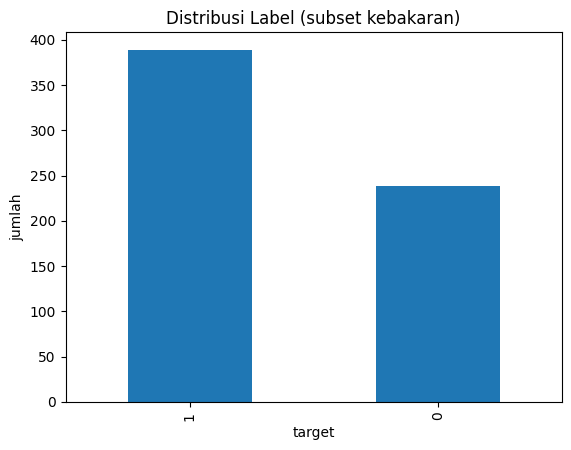

target
0    14.642857
1    13.526992
Name: panjang, dtype: float64
[('the', 283), ('fire', 245), ('in', 180), ('to', 167), ('a', 150), ('on', 128), ('of', 128), ('i', 126), ('burning', 111), ('and', 108), ('fires', 100), ('buildings', 93), ('california', 82), ('you', 82), ('is', 82)]


In [5]:
dk = pd.read_csv('data/data_bersih_kebakaran.csv')
print(dk.shape)

# Distribusi label
print(dk['target'].value_counts())
dk['target'].value_counts().plot(kind='bar')
plt.title('Distribusi Label (subset kebakaran)')
plt.xlabel('target'); plt.ylabel('jumlah')
plt.show()

# Rata-rata panjang teks per label
dk['panjang'] = dk['clean_text'].str.split().str.len()
print(dk.groupby('target')['panjang'].mean())

# 15 kata paling sering
kata = ' '.join(dk['clean_text']).split()
print(Counter(kata).most_common(15))

## Tahap 4. Feature Selection (TF-IDF)

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(stop_words='english', max_features=3000)
Xk = vec.fit_transform(dk['clean_text'])
print(Xk.shape)

# 15 kata dengan bobot TF-IDF tertinggi
bobot = Xk.sum(axis=0).A1
nama_kata = vec.get_feature_names_out()
top = pd.Series(bobot, index=nama_kata).sort_values(ascending=False).head(15)
print(top)

(627, 2208)
burning       21.654560
california    19.583874
fires         19.179524
buildings     18.309710
wildfire      16.314167
northern      13.651979
homes         13.094870
smoke         12.656699
forest        12.072754
latest        11.702451
razed         11.410272
amp           10.073655
like           9.817088
truck          8.715962
wild           8.125852
dtype: float64


## Tahap 5. Train-Test Split (80:20)

In [7]:
from sklearn.model_selection import train_test_split

dl = pd.read_csv('data/data_bersih_lengkap.csv')
X = dl['clean_text']
y = dl['target']
fire = dl['is_fire']

X_train, X_test, y_train, y_test, f_train, f_test = train_test_split(
    X, y, fire, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

# TF-IDF: fit hanya pada data latih (mencegah data leakage)
vektor = TfidfVectorizer(stop_words='english', max_features=5000)
X_train_vec = vektor.fit_transform(X_train)
X_test_vec = vektor.transform(X_test)

Data latih: 6002 | Data uji: 1501


## Tahap 6. Pemodelan (2 Algoritma)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Algoritma 1: Logistic Regression
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_vec, y_train)

# Algoritma 2: Multinomial Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)

# Simpan model dan vectorizer
joblib.dump(lr, 'model/model_logistic_regression.pkl')
joblib.dump(nb, 'model/model_naive_bayes.pkl')
joblib.dump(vektor, 'model/vectorizer_kebakaran.pkl')
print("Pelatihan selesai, model tersimpan di folder model/")

Pelatihan selesai, model tersimpan di folder model/


## Tahap 7. Evaluasi Model

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

y_arr = np.array(y_test)
mask = (np.array(f_test) == 1)

def hitung(model, X, y):
    p = model.predict(X)
    return [accuracy_score(y, p), precision_score(y, p),
            recall_score(y, p), f1_score(y, p)]

hasil = []
for nama, model in [('Logistic Regression', lr), ('Multinomial NB', nb)]:
    hasil.append([nama, 'Semua data uji'] + hitung(model, X_test_vec, y_arr))
    hasil.append([nama, 'Subset kebakaran'] + hitung(model, X_test_vec[mask], y_arr[mask]))

tabel = pd.DataFrame(hasil, columns=['Model', 'Cakupan', 'Accuracy', 'Precision', 'Recall', 'F1']).round(3)
tabel

,Model,Cakupan,Accuracy,Precision,Recall,F1
0,Logistic Regression,Semua data uji,0.801,0.787,0.733,0.759
1,Logistic Regression,Subset kebakaran,0.802,0.771,0.900,0.831
2,Multinomial NB,Semua data uji,0.807,0.838,0.680,0.751
3,Multinomial NB,Subset kebakaran,0.784,0.810,0.783,0.797


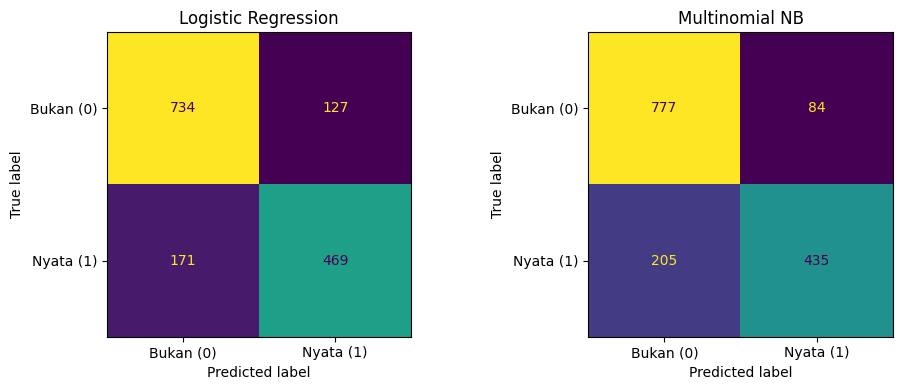

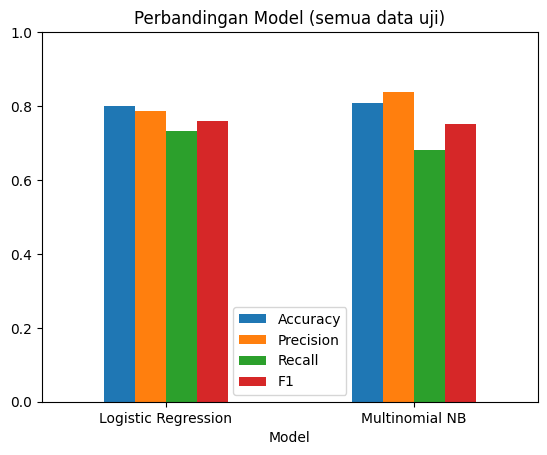

In [10]:
# Confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nama, model) in zip(ax, [('Logistic Regression', lr), ('Multinomial NB', nb)]):
    cm = confusion_matrix(y_arr, model.predict(X_test_vec))
    ConfusionMatrixDisplay(cm, display_labels=['Bukan (0)', 'Nyata (1)']).plot(ax=a, colorbar=False)
    a.set_title(nama)
plt.tight_layout()
plt.show()

# Grafik perbandingan model
(tabel[tabel['Cakupan'] == 'Semua data uji']
 .set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']]
 .plot(kind='bar', rot=0))
plt.title('Perbandingan Model (semua data uji)')
plt.ylim(0, 1)
plt.savefig('model/perbandingan_model.png', bbox_inches='tight')
plt.show()

In [11]:
# Cross-validation 5-fold
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(
    TfidfVectorizer(stop_words='english', max_features=5000),
    LogisticRegression(max_iter=1000, class_weight='balanced'))
skor = cross_val_score(pipe, dl['clean_text'], dl['target'], cv=5, scoring='accuracy')
print("Skor tiap lipatan:", skor.round(3))
print("Rata-rata akurasi:", round(skor.mean(), 3))
print("Memenuhi minimal 50%?", "YA" if skor.mean() >= 0.5 else "TIDAK")

Skor tiap lipatan: [0.716 0.62  0.662 0.688 0.745]
Rata-rata akurasi: 0.686
Memenuhi minimal 50%? YA


## Tahap 8. Prediksi dan Interpretasi
Laporan berbahasa Indonesia diterjemahkan ke Inggris, dibersihkan, lalu diprediksi. Peluang ≥ 0,60 = DARURAT, ≤ 0,40 = BUKAN KEJADIAN NYATA, di antaranya = PERLU DITINJAU.

In [12]:
from deep_translator import GoogleTranslator, MyMemoryTranslator

BATAS_DARURAT = 0.60
BATAS_TIDAK_DARURAT = 0.40

def terjemahkan(teks, percobaan=3):
    for _ in range(percobaan):
        try:
            return GoogleTranslator(source='id', target='en').translate(teks)
        except Exception:
            time.sleep(2)
    return MyMemoryTranslator(source='id-ID', target='en-US').translate(teks)

def prediksi_laporan(laporan):
    inggris = terjemahkan(laporan)
    bersih = clean_text(inggris)
    proba = lr.predict_proba(vektor.transform([bersih]))[0][1]

    if proba >= BATAS_DARURAT:
        label, saran = 'DARURAT (indikasi kejadian nyata)', 'Segera teruskan ke petugas/BPBD untuk verifikasi'
    elif proba <= BATAS_TIDAK_DARURAT:
        label, saran = 'BUKAN KEJADIAN NYATA / TIDAK RELEVAN', 'Arsipkan atau pantau sebagai informasi umum'
    else:
        label, saran = 'PERLU DITINJAU', 'Tinjau manual oleh petugas'

    print(f'Laporan   : {laporan}')
    print(f'Terjemahan: {inggris}')
    print(f'Peluang   : {proba:.1%}')
    print(f'Keputusan : {label}')
    print(f'Saran     : {saran}')
    print('-' * 60)
    return label, proba

In [15]:
# Ganti dengan laporan uji Anda sendiri
laporan_uji = [
    'Terlihat api besar membakar hutan dekat desa kami',
    'Asap tebal menyelimuti kawasan hutan sejak semalam',
    'Hari ini ada penyuluhan pencegahan kebakaran hutan di balai desa',
    'Semangat belajarku membara lagi membara kayak api',
    'Lagu terbaru band ini benar-benar fire, wajib didengar'
]
for l in laporan_uji:
    prediksi_laporan(l)
    time.sleep(1)

Laporan   : Terlihat api besar membakar hutan dekat desa kami
Terjemahan: A large fire was seen burning the forest near our village
Peluang   : 87.1%
Keputusan : DARURAT (indikasi kejadian nyata)
Saran     : Segera teruskan ke petugas/BPBD untuk verifikasi
------------------------------------------------------------
Laporan   : Asap tebal menyelimuti kawasan hutan sejak semalam
Terjemahan: Thick smoke blanketed the forest area since yesterday
Peluang   : 67.0%
Keputusan : DARURAT (indikasi kejadian nyata)
Saran     : Segera teruskan ke petugas/BPBD untuk verifikasi
------------------------------------------------------------
Laporan   : Hari ini ada penyuluhan pencegahan kebakaran hutan di balai desa
Terjemahan: Today there is counseling on forest fire prevention at the village hall
Peluang   : 67.9%
Keputusan : DARURAT (indikasi kejadian nyata)
Saran     : Segera teruskan ke petugas/BPBD untuk verifikasi
------------------------------------------------------------
Laporan   : Semangat

In [14]:
# (Opsional) Unduh model ke komputer
from google.colab import files
for f in ['model_logistic_regression.pkl', 'model_naive_bayes.pkl', 'vectorizer_kebakaran.pkl']:
    files.download('model/' + f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>